First 5 Rows:
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  woman       False    C  Southampton   yes  False  
4    man        True  NaN  Southampton    no   True  

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -

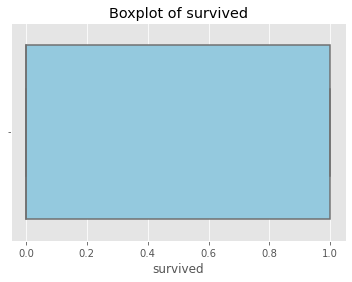

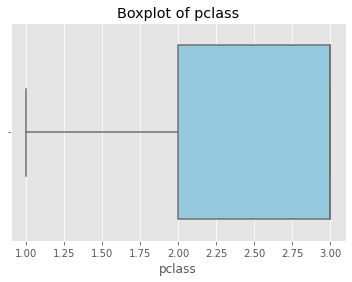

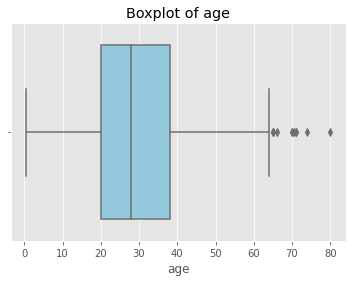

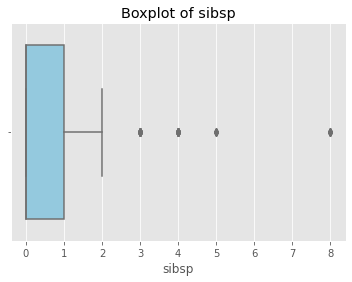

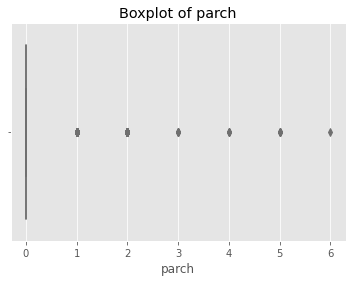

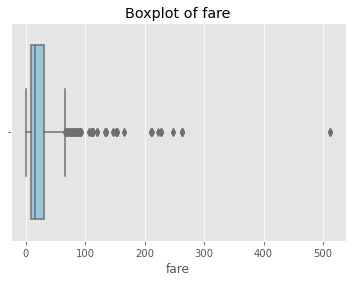

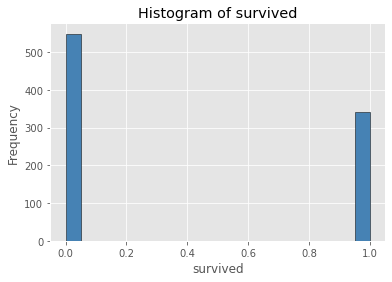

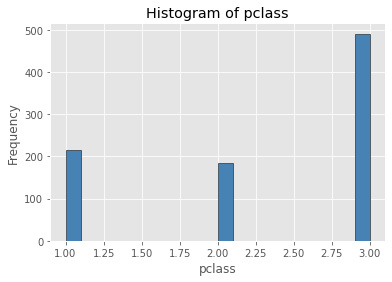

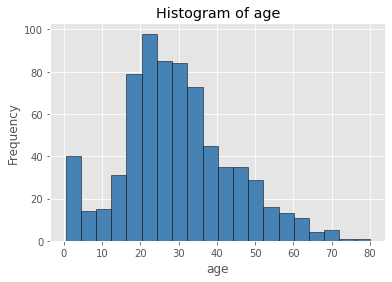

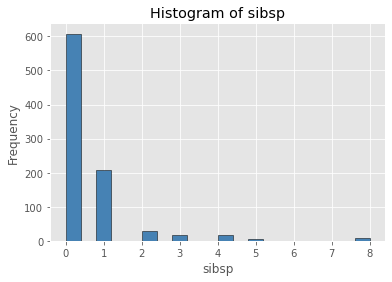

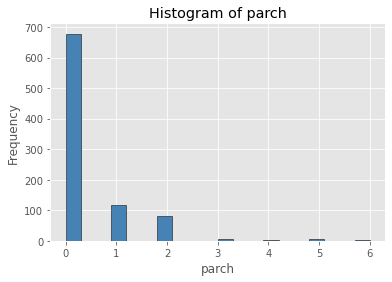

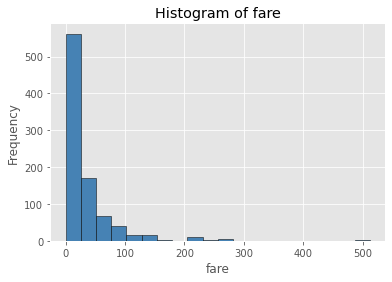

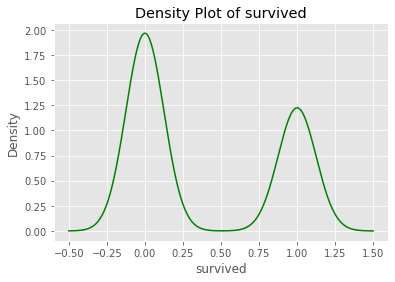

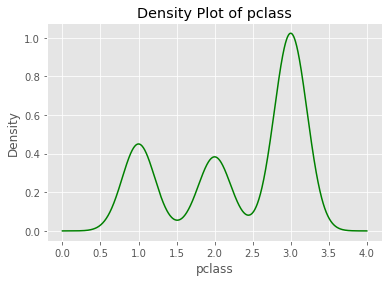

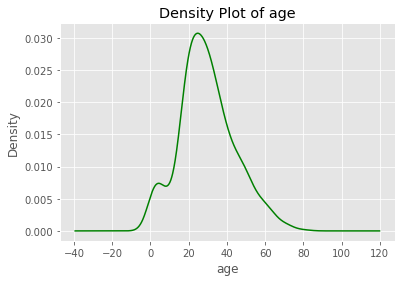

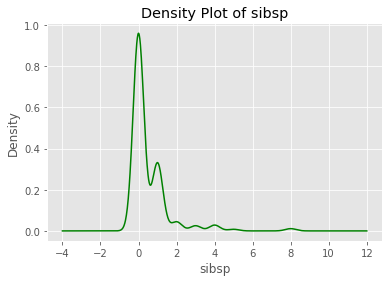

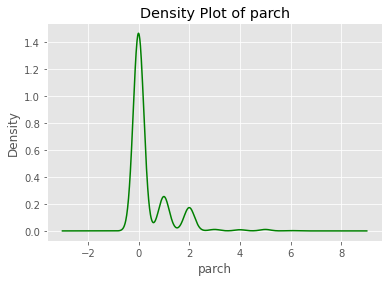

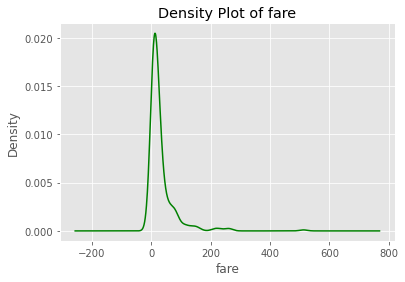

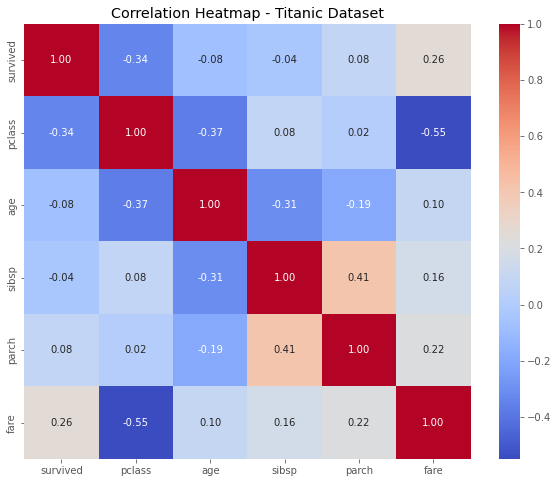

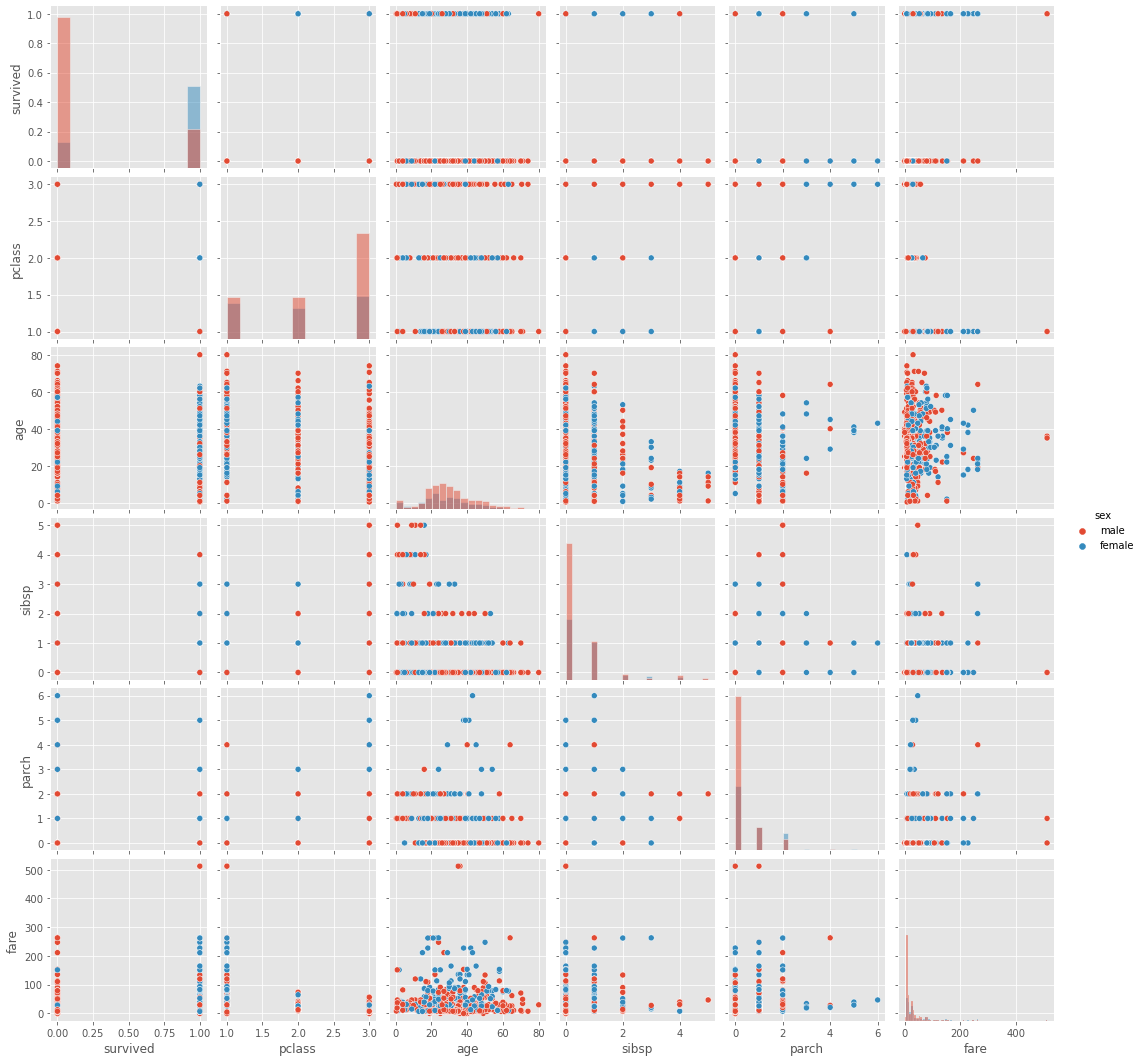

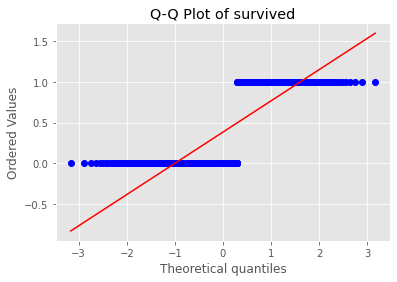

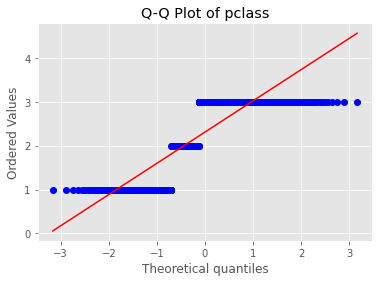

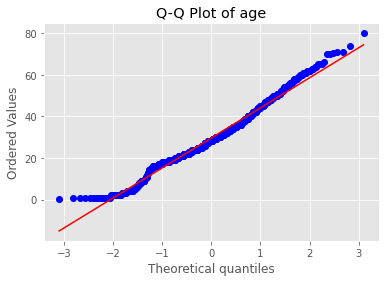

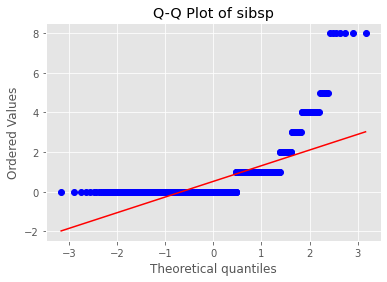

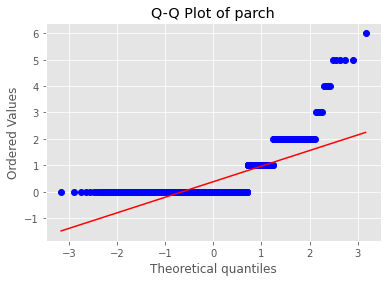

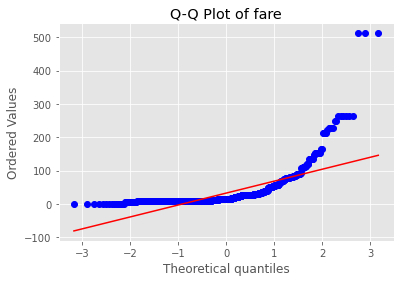


========== Analysis Completed Successfully! ==========


In [2]:
# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import trim_mean, median_abs_deviation
from scipy.stats import probplot

# Plot style
plt.style.use('ggplot')

# ---------------------------------------
# LOAD TITANIC DATASET
# ---------------------------------------
df = sns.load_dataset("titanic")

# Display first 5 rows
print("First 5 Rows:")
print(df.head())

# Dataset Information
print("\nDataset Information:")
print(df.info())

# Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Select only numerical columns
num_df = df.select_dtypes(include=np.number)

print("\nNumerical Columns:")
print(num_df.columns)

# ---------------------------------------
# DESCRIPTIVE STATISTICS
# ---------------------------------------
print("\n========== DESCRIPTIVE STATISTICS ==========\n")

for col in num_df.columns:
    data = num_df[col].dropna()

    print(f"\n----- {col} -----")

    # Mean
    print("Mean:", data.mean())

    # Median
    print("Median:", data.median())

    # Trimmed Mean (10%)
    print("Trimmed Mean:", trim_mean(data, 0.10))

    # Weighted Mean
    weights = np.arange(1, len(data) + 1)
    print("Weighted Mean:", np.average(data, weights=weights))

    # Range
    print("Range:", data.max() - data.min())

    # Variance
    print("Variance:", data.var())

    # Standard Deviation
    print("Standard Deviation:", data.std())

    # Interquartile Range
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    print("IQR:", Q3 - Q1)

    # Median Absolute Deviation
    print("Median Absolute Deviation:",
          median_abs_deviation(data))

# ---------------------------------------
# VISUALIZATIONS
# ---------------------------------------

# 1. Boxplots
for col in num_df.columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=num_df[col], color='skyblue')
    plt.title(f'Boxplot of {col}')
    plt.xlabel(col)
    plt.show()

# 2. Histograms
for col in num_df.columns:
    plt.figure(figsize=(6,4))
    plt.hist(num_df[col].dropna(),
             bins=20,
             color='steelblue',
             edgecolor='black')
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

# 3. Density Plots
for col in num_df.columns:
    plt.figure(figsize=(6,4))
    num_df[col].dropna().plot(kind='density', color='green')
    plt.title(f'Density Plot of {col}')
    plt.xlabel(col)
    plt.show()

# 4. Correlation Heatmap
plt.figure(figsize=(10,8))
sns.heatmap(num_df.corr(),
            annot=True,
            cmap='coolwarm',
            fmt='.2f')
plt.title("Correlation Heatmap - Titanic Dataset")
plt.show()

# 5. Scatter Plot Matrix (Pair Plot)
pair_df = df[['survived','pclass','age','sibsp','parch','fare','sex']].dropna()

sns.pairplot(pair_df,
             hue='sex',
             diag_kind='hist')
plt.show()

# 6. Q-Q Plots
for col in num_df.columns:
    plt.figure(figsize=(6,4))
    probplot(num_df[col].dropna(),
             dist="norm",
             plot=plt)
    plt.title(f'Q-Q Plot of {col}')
    plt.show()

print("\n========== Analysis Completed Successfully! ==========")


# In[ ]:
